In [1]:
%pip install pandas numpy matplotlib seaborn scikit-learn joblib --quiet

Note: you may need to restart the kernel to use updated packages.


In [ ]:
import os, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix,
                             classification_report, ConfusionMatrixDisplay)

%matplotlib inline
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

In [3]:
CSV = "alzheimers_disease_data.csv"

if os.path.exists(CSV):
    df = pd.read_csv(CSV)
elif os.path.exists("archive.zip"):
    with zipfile.ZipFile("archive.zip") as z:
        with z.open(CSV) as f:
            df = pd.read_csv(f)
else:
    raise FileNotFoundError("Put alzheimers_disease_data.csv (or archive.zip) next to this notebook.")

print("Shape:", df.shape)
df.head()

Shape: (2149, 35)


,PatientID,Age,Gender,Ethnicity,EducationLevel,BMI,Smoking,AlcoholConsumption,PhysicalActivity,DietQuality,...,MemoryComplaints,BehavioralProblems,ADL,Confusion,Disorientation,PersonalityChanges,DifficultyCompletingTasks,Forgetfulness,Diagnosis,DoctorInCharge
0,4751,73,0,0,2,22.927749,0,13.297218,6.327112,1.347214,...,0,0,1.725883,0,0,0,1,0,0,XXXConfid
1,4752,89,0,0,0,26.827681,0,4.542524,7.619885,0.518767,...,0,0,2.592424,0,0,0,0,1,0,XXXConfid
2,4753,73,0,3,1,17.795882,0,19.555085,7.844988,1.826335,...,0,0,7.119548,0,1,0,1,0,0,XXXConfid
3,4754,74,1,0,1,33.800817,1,12.209266,8.428001,7.435604,...,0,1,6.481226,0,0,0,0,0,0,XXXConfid
4,4755,89,0,0,0,20.716974,0,18.454356,6.310461,0.795498,...,0,0,0.014691,0,0,1,1,0,0,XXXConfid


Missing values: 0
Duplicate rows: 0

Diagnosis
No Alzheimer's    1389
Alzheimer's        760
Name: count, dtype: int64


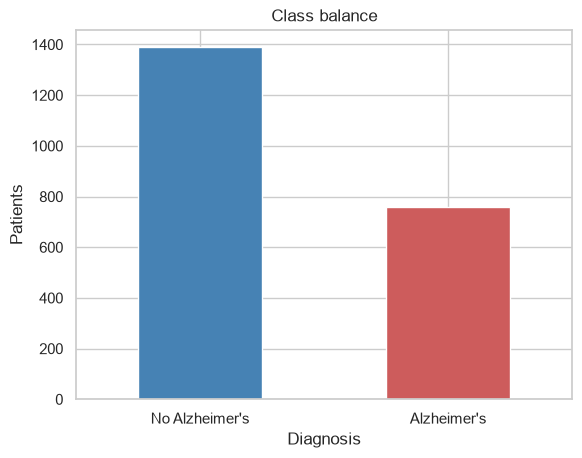

In [4]:
print("Missing values:", int(df.isna().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))
print()
print(df["Diagnosis"].value_counts().rename({0: "No Alzheimer's", 1: "Alzheimer's"}))

df["Diagnosis"].value_counts().rename({0: "No Alzheimer's", 1: "Alzheimer's"}).plot(
    kind="bar", color=["steelblue", "indianred"], rot=0)
plt.title("Class balance")
plt.ylabel("Patients")
plt.show()

In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
PatientID,2149.0,5825.000000,620.507185,4751.000000,5288.000000,5825.000000,6362.000000,6899.000000
Age,2149.0,74.908795,8.990221,60.000000,67.000000,75.000000,83.000000,90.000000
Gender,2149.0,0.506282,0.500077,0.000000,0.000000,1.000000,1.000000,1.000000
Ethnicity,2149.0,0.697534,0.996128,0.000000,0.000000,0.000000,1.000000,3.000000
EducationLevel,2149.0,1.286645,0.904527,0.000000,1.000000,1.000000,2.000000,3.000000
BMI,2149.0,27.655697,7.217438,15.008851,21.611408,27.823924,33.869778,39.992767
Smoking,2149.0,0.288506,0.453173,0.000000,0.000000,0.000000,1.000000,1.000000
AlcoholConsumption,2149.0,10.039442,5.757910,0.002003,5.139810,9.934412,15.157931,19.989293
PhysicalActivity,2149.0,4.920202,2.857191,0.003616,2.570626,4.766424,7.427899,9.987429
DietQuality,2149.0,4.993138,2.909055,0.009385,2.458455,5.076087,7.558625,9.998346


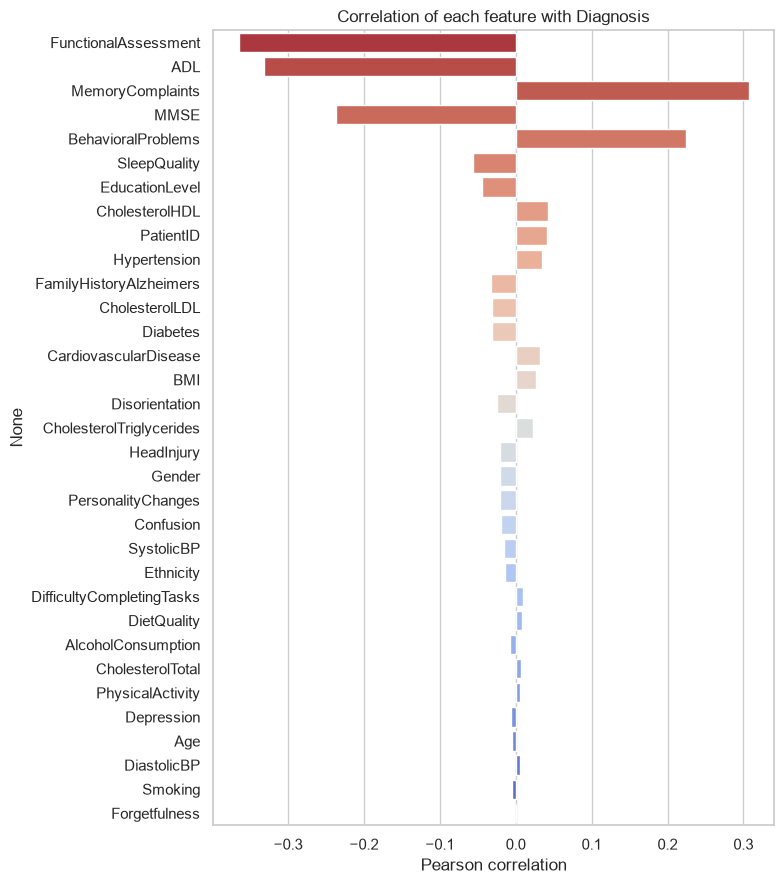

In [6]:
corr = df.drop(columns=["DoctorInCharge"]).corr(numeric_only=True)["Diagnosis"].drop("Diagnosis")
corr = corr.reindex(corr.abs().sort_values(ascending=False).index)

plt.figure(figsize=(8, 9))
sns.barplot(x=corr.values, y=corr.index, palette="coolwarm_r", hue=corr.index, legend=False)
plt.title("Correlation of each feature with Diagnosis")
plt.xlabel("Pearson correlation")
plt.tight_layout()
plt.show()

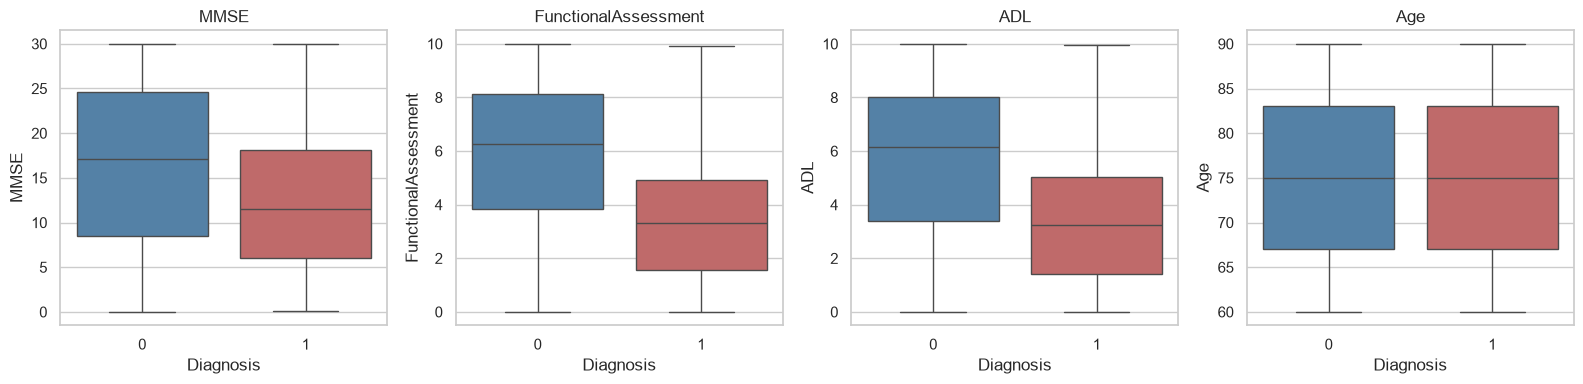

In [7]:
key = ["MMSE", "FunctionalAssessment", "ADL", "Age"]
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, col in zip(axes, key):
    sns.boxplot(data=df, x="Diagnosis", y=col, hue="Diagnosis", palette=["steelblue", "indianred"],
                legend=False, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

In [8]:
X = df.drop(columns=["Diagnosis", "PatientID", "DoctorInCharge"])
y = df["Diagnosis"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (1719, 32) | Test: (430, 32)


In [9]:
models = {
    "SVM": Pipeline([
        ("scale", StandardScaler()),
        ("clf", CalibratedClassifierCV(SVC(kernel="rbf"), ensemble=False, cv=5)),
    ]),
    "KNN": Pipeline([
        ("scale", StandardScaler()),
        ("clf", KNeighborsClassifier(n_neighbors=7)),
    ]),
    "Decision Tree": DecisionTreeClassifier(max_depth=6, random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1),
    "Gradient Boosting": GradientBoostingClassifier(random_state=RANDOM_STATE),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
rows = []
for name, model in models.items():
    scores = cross_val_score(model, X_train, y_train, cv=cv, scoring="roc_auc")
    rows.append({"Model": name, "CV ROC-AUC (mean)": scores.mean(), "Std": scores.std()})

cv_results = pd.DataFrame(rows).sort_values("CV ROC-AUC (mean)", ascending=False)
cv_results

,Model,CV ROC-AUC (mean),Std
3,Random Forest,0.956078,0.012875
4,Gradient Boosting,0.954342,0.011797
2,Decision Tree,0.914458,0.014816
0,SVM,0.894477,0.014857
1,KNN,0.770442,0.020352


In [10]:
results, fitted, probas = [], {}, {}

for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    proba = model.predict_proba(X_test)[:, 1]
    fitted[name], probas[name] = model, proba
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, proba),
    })

results_df = pd.DataFrame(results).set_index("Model").sort_values("ROC-AUC", ascending=False)
best_name = results_df.index[0]
print("Best model on test set:", best_name)
results_df.round(3)

Best model on test set: Gradient Boosting


,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Gradient Boosting,0.947,0.927,0.921,0.924,0.946
Random Forest,0.949,0.945,0.908,0.926,0.940
Decision Tree,0.928,0.895,0.901,0.898,0.912
SVM,0.835,0.772,0.757,0.764,0.896
KNN,0.709,0.645,0.395,0.490,0.765


                precision    recall  f1-score   support

No Alzheimer's       0.96      0.96      0.96       278
   Alzheimer's       0.93      0.92      0.92       152

      accuracy                           0.95       430
     macro avg       0.94      0.94      0.94       430
  weighted avg       0.95      0.95      0.95       430



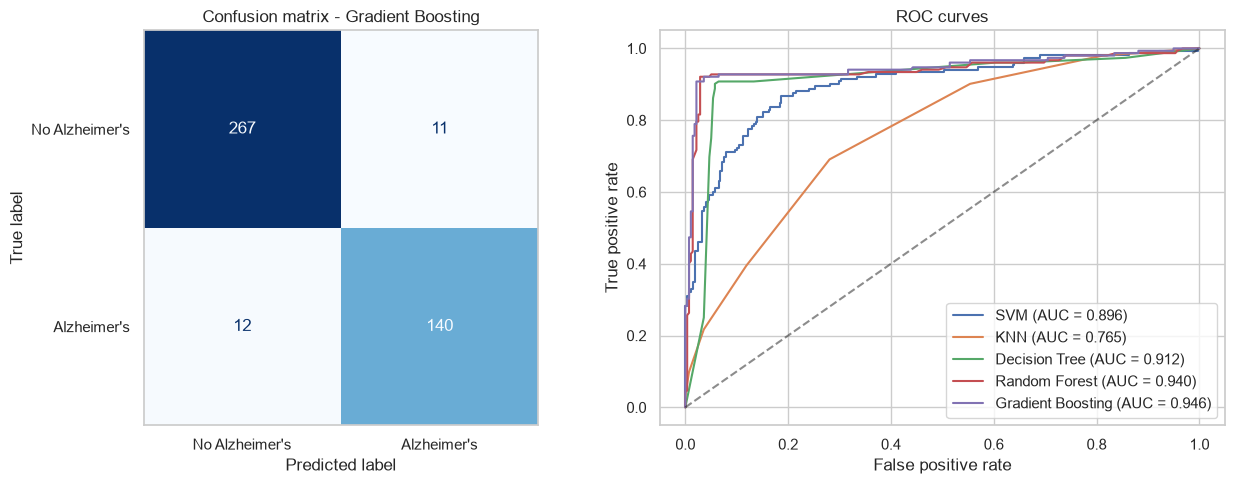

In [11]:
best = fitted[best_name]
best_pred = best.predict(X_test)

print(classification_report(y_test, best_pred, target_names=["No Alzheimer's", "Alzheimer's"]))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

ConfusionMatrixDisplay(confusion_matrix(y_test, best_pred),
                       display_labels=["No Alzheimer's", "Alzheimer's"]).plot(
    ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title(f"Confusion matrix - {best_name}")
axes[0].grid(False)

for name, proba in probas.items():
    fpr, tpr, _ = roc_curve(y_test, proba)
    axes[1].plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_test, proba):.3f})")
axes[1].plot([0, 1], [0, 1], "k--", alpha=0.5)
axes[1].set_xlabel("False positive rate")
axes[1].set_ylabel("True positive rate")
axes[1].set_title("ROC curves")
axes[1].legend()

plt.tight_layout()
plt.show()

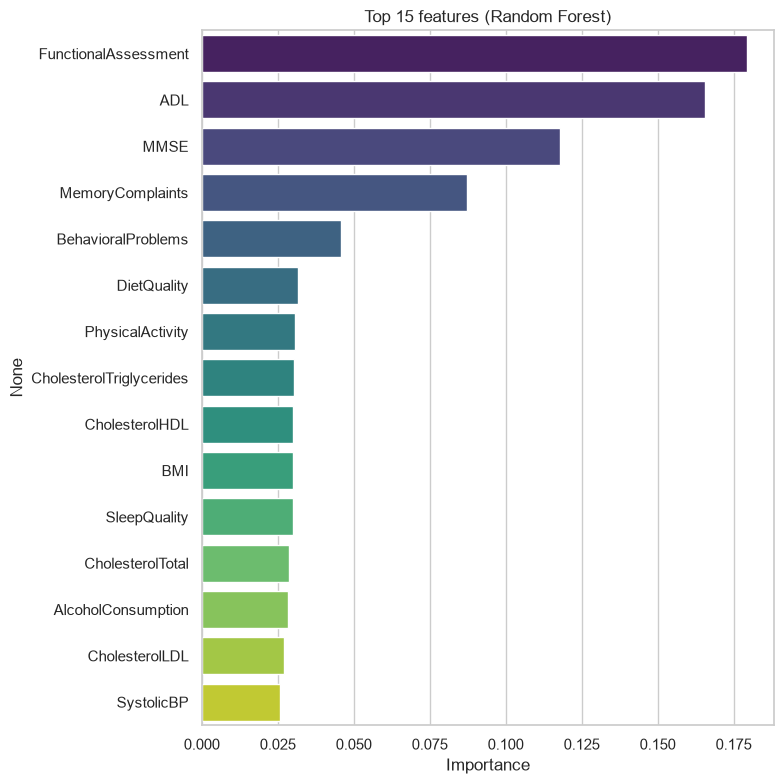

In [ ]:
rf = fitted["Random Forest"]
importances = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)

plt.figure(figsize=(8, 8))
sns.barplot(x=importances.head(15).values, y=importances.head(15).index,
            hue=importances.head(15).index, palette="viridis", legend=False)
plt.title("Top 15 features (Random Forest) ")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

In [13]:
joblib.dump({"model": best, "features": list(X.columns), "defaults": X.median().to_dict(), "name": best_name}, "alzheimers_model.joblib")
print("Saved alzheimers_model.joblib")

Saved alzheimers_model.joblib


In [26]:
import os
import joblib
import pandas as pd

if not os.path.exists("alzheimers_model.joblib"):
    raise FileNotFoundError("Run the training cells above first so alzheimers_model.joblib is created.")

saved = joblib.load("alzheimers_model.joblib")
model = saved["model"]
features = saved["features"]
defaults = saved["defaults"]

def predict_patient(values: dict):
    row = pd.DataFrame([defaults])[features]
    for k, v in values.items():
        if k not in row.columns:
            raise KeyError(f"Unknown feature: {k}")
        row[k] = v
    prob = model.predict_proba(row)[0, 1]
    label = "Alzheimer's likely" if prob >= 0.5 else "Alzheimer's unlikely"
    return label, prob

patient1 = {
    "Age": 20,
    "MMSE": 4,
    "FunctionalAssessment": 1,
    "ADL": 1,
    "MemoryComplaints": 0,
    "Forgetfulness": 0,
    "FamilyHistoryAlzheimers": 0,
}

label, prob = predict_patient(patient1)
print(f"{label}  (probability of Alzheimer's: {prob:.1%})")

Alzheimer's likely  (probability of Alzheimer's: 93.1%)


In [27]:
patient2 = {
    "Age": 68,
    "MMSE": 24,
    "FunctionalAssessment": 7,
    "ADL": 7,
    "MemoryComplaints": 0,
    "BehavioralProblems": 0,
    "Forgetfulness": 0,
    "FamilyHistoryAlzheimers": 0,
}


label, prob = predict_patient(patient2)
print(f"{label}  (probability of Alzheimer's: {prob:.1%})")

Alzheimer's unlikely  (probability of Alzheimer's: 1.0%)
